# Encontro 4 · LangGraph do zero: agentes como grafos

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/se-ai-agents-engineering/ai-agents-engineering-v2/blob/main/encontro-04/03-langgraph.ipynb)

Nos Encontros 2 e 3, o agente da Aurora foi um laço escrito à mão: chama o modelo, executa a ferramenta que ele pediu, devolve o resultado, chama o modelo de novo, até ele encerrar. No notebook 01 deste encontro, vários desses laços passaram a ser coordenados por um roteador ou por um supervisor, também à mão.

O **LangGraph** escreve a mesma coisa de outro jeito: como um **grafo**. Cada passo vira um **nó** com nome, cada decisão vira uma **aresta**, e tudo o que o atendimento já sabe fica num **estado** que o framework guarda a cada passo. Neste notebook você constrói isso do zero: primeiro um grafo de um nó só, depois o agente da Aula 3, depois o roteador com especialistas e, por fim, as duas coisas que o laço à mão não faz: **retomar de onde parou** e **esperar uma pessoa**.

### O que você vai sair sabendo

- Montar um grafo em LangGraph: estado, nós, arestas fixas e arestas condicionais.
- Escrever o agente que decide buscar como um grafo, e reconhecer nele o laço dos Encontros 2 e 3.
- Escrever o roteador com especialistas, do notebook 01, como um grafo.
- Usar um checkpointer para retomar um atendimento depois de uma falha.
- Pausar o grafo para uma aprovação humana antes de uma ação irreversível.
- Dizer quando o LangGraph se paga e quando é estrutura demais.

### Mapa do notebook

| Parte | O que você constrói | Usa o modelo? |
|---|---|---|
| 0 · Ambiente | — | não |
| 1 · O grafo mínimo | um grafo de um nó | não |
| 2 · Uma sequência | dois nós em fila, com um estado que acumula | não |
| 3 · Uma decisão | uma aresta condicional: o código escolhe o caminho | não |
| 4 · O agente | o agente da Aula 3 como grafo: o modelo escolhe o caminho | sim |
| 5 · Vários agentes | o roteador com especialistas como grafo | sim |
| 6 · Quando algo falha | checkpoint e retomada | sim |
| 7 · Esperar uma pessoa | pausa para aprovação humana | sim |
| 8 · Síntese | o que o LangGraph deu, e o que continuou seu | não |

As Partes 1 a 3 não chamam o modelo: elas mostram o LangGraph sem distração. A partir da Parte 4, o grafo passa a chamar o modelo.

### Peças que você já conhece

O modelo continua sendo chamado pelo `comum/modelo.py`, a busca é a do Encontro 3, e cada ferramenta passa pela camada do Encontro 2. O roteador e os especialistas são os do notebook 01. **O LangGraph organiza os passos e guarda o estado; ele não substitui nada do que a turma construiu.** Por isso este notebook também roda sem chave: as respostas do modelo vêm da mesma gravação dos notebooks 01 e 02.

## Etapa 0 · Ambiente

No Colab, a célula abaixo baixa o repositório e instala o LangGraph, em menos de um minuto. Apareceu "Tudo certo, pode seguir"? Pode seguir.

In [1]:
# Etapa 0 · No Colab, baixa o repositório e instala o LangGraph.
# Na sua máquina, instale antes: pip install -r encontro-04/requirements-demo.txt
import os, sys, subprocess
if "google.colab" in sys.modules:
    if not os.path.exists("/content/ai-agents-engineering"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/se-ai-agents-engineering/ai-agents-engineering-v2",
                        "/content/ai-agents-engineering"], check=True)
    os.chdir("/content/ai-agents-engineering/encontro-04")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "python-dotenv", "langgraph>=1.0,<2"],
                   check=True)
sys.path.insert(0, os.getcwd())

import json
import multiagente as ma
from comum import medidor, modelo
ma.preparar("usar")
casos = {c["id"]: c for c in ma.carregar_casos()}

import langgraph  # noqa: F401
print("LangGraph instalado. Tudo certo, pode seguir.")

Replay 'usar': 333 respostas gravadas com gpt-4o-mini em 2026-10-12 15:36
Há chave configurada: o que não estiver gravado será chamado ao vivo, com custo.
Busca: 90 trechos da wiki da Aurora, espaços confluence-rh, wiki-beneficios, wiki-financeiro, wiki-rh, wiki-ti
LangGraph instalado. Tudo certo, pode seguir.


A célula seguinte define `desenhar`, uma função auxiliar para ver o grafo como diagrama. Ela não é do LangGraph: só chama o desenho que ele já sabe fazer.

In [2]:
# Desenha um grafo. No Colab, vira uma imagem; sem internet, sai o texto do diagrama (Mermaid).
def desenhar(grafo):
    try:
        from IPython.display import Image, display
        get_ipython()  # noqa: F821  (só existe dentro do Jupyter ou do Colab)
        display(Image(grafo.get_graph().draw_mermaid_png()))
    except Exception:
        print(grafo.get_graph().draw_mermaid())

## Parte 1 · O grafo mínimo

**Produz:** `grafo_minimo`, um grafo com um único nó.

Um grafo do LangGraph tem três ingredientes:

| Ingrediente | O que é | No código |
|---|---|---|
| **Estado** | Um dicionário tipado com tudo o que o processo sabe | uma classe `TypedDict` |
| **Nó** | Uma função que recebe o estado e devolve **só o que mudou** | uma função Python comum |
| **Aresta** | Diz qual nó vem depois | `add_edge(origem, destino)` |

`START` e `END` são dois nós especiais, que marcam a entrada e a saída. O caminho é sempre o mesmo: você descreve o grafo num **construtor** (`StateGraph`), **compila** e depois **invoca** com um estado inicial.

In [3]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


class EstadoSimples(TypedDict, total=False):
    pergunta: str
    resposta: str


def responder(estado: EstadoSimples) -> dict:
    return {"resposta": f"Recebi a sua pergunta: {estado['pergunta']}"}


construtor = StateGraph(EstadoSimples)
construtor.add_node("responder", responder)
construtor.add_edge(START, "responder")
construtor.add_edge("responder", END)
grafo_minimo = construtor.compile()

grafo_minimo.invoke({"pergunta": "Quantos dias de férias eu tenho?"})

{'pergunta': 'Quantos dias de férias eu tenho?',
 'resposta': 'Recebi a sua pergunta: Quantos dias de férias eu tenho?'}

### Como ler a saída

`invoke` devolve o **estado final**: a pergunta, que veio da entrada, e a resposta, que o nó acrescentou. Repare que o nó `responder` devolveu só `{"resposta": ...}`, e não o estado inteiro. **Quem junta o que cada nó devolve com o que já estava no estado é o LangGraph.** Essa é a regra que torna os nós pequenos: cada um cuida só do que muda.

E o desenho do grafo:

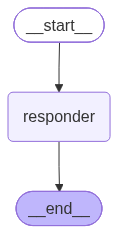

In [4]:
desenhar(grafo_minimo)

## Parte 2 · Uma sequência, e um estado que acumula

**Produz:** `triagem`, um grafo com dois nós em fila.

Agora dois nós: um limpa a pergunta, e o outro a classifica por área com o roteador por palavras-chave do notebook 01, que não usa o modelo.

O estado ganha um campo novo, `passos`, com uma anotação diferente: `Annotated[list, operator.add]`. Ela diz ao LangGraph **como juntar** o que cada nó devolve nesse campo. Sem a anotação, o valor novo **substitui** o anterior. Com `operator.add`, as listas são **somadas**: cada nó acrescenta a sua linha, e o estado acumula o histórico. Isso se chama **reducer**, e é o jeito do LangGraph de dizer, campo a campo, se o valor substitui o anterior ou se acumula.

In [5]:
import operator
from typing import Annotated


class EstadoTriagem(TypedDict, total=False):
    pergunta: str
    area: str
    passos: Annotated[list, operator.add]     # cada nó acrescenta; o LangGraph soma as listas


def normalizar(estado: EstadoTriagem) -> dict:
    texto = " ".join(estado["pergunta"].split())
    return {"pergunta": texto, "passos": ["normalizar"]}


def classificar(estado: EstadoTriagem) -> dict:
    rota = ma.rotear_com_regra(estado["pergunta"], ma.equipe(3), [])     # palavras-chave, sem modelo
    return {"area": rota["destino"], "passos": [f"classificar → {rota['destino']}"]}


construtor = StateGraph(EstadoTriagem)
construtor.add_node("normalizar", normalizar)
construtor.add_node("classificar", classificar)
construtor.add_edge(START, "normalizar")
construtor.add_edge("normalizar", "classificar")
construtor.add_edge("classificar", END)
triagem = construtor.compile()

Em vez de `invoke`, que só devolve o fim, use `stream` para ver o grafo andar. Com `stream_mode="updates"`, cada item é um dicionário `{nome do nó: o que ele devolveu}`, um por passo:

In [6]:
for atualizacao in triagem.stream({"pergunta": "  Estou com o erro 809   na VPN  "}, stream_mode="updates"):
    print(atualizacao)

{'normalizar': {'pergunta': 'Estou com o erro 809 na VPN', 'passos': ['normalizar']}}
{'classificar': {'area': 'ti', 'passos': ['classificar → ti']}}


**Pergunta para a turma.** O campo `pergunta` foi devolvido pelo `normalizar` e substituiu o valor de entrada. O campo `passos` foi devolvido pelos dois nós e acumulou. O que decide a diferença?

## Parte 3 · Uma decisão: a aresta condicional

**Produz:** uma `triagem` nova, que segue caminhos diferentes conforme a área.

Até aqui, o caminho era fixo. Uma **aresta condicional** escolhe o próximo nó lendo o estado: você passa uma função que olha o estado e devolve uma chave, e um dicionário que liga cada chave a um nó.

Aqui, quem escolhe ainda é o **código**: a área veio de palavras-chave, e a função `depois_de_classificar` é um `if`. Isto é um **workflow**, como no Encontro 1. A próxima parte troca quem decide.

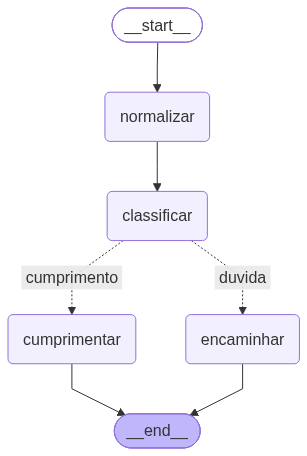

In [7]:
def cumprimentar(estado: EstadoTriagem) -> dict:
    return {"passos": ["cumprimentar: resposta pronta, sem consultar nada"]}


def encaminhar(estado: EstadoTriagem) -> dict:
    return {"passos": [f"encaminhar para a fila de {estado['area']}"]}


def depois_de_classificar(estado: EstadoTriagem) -> str:
    return "cumprimento" if estado["area"] == "geral" else "duvida"


construtor = StateGraph(EstadoTriagem)
for nome, fn in [("normalizar", normalizar), ("classificar", classificar),
                 ("cumprimentar", cumprimentar), ("encaminhar", encaminhar)]:
    construtor.add_node(nome, fn)
construtor.add_edge(START, "normalizar")
construtor.add_edge("normalizar", "classificar")
construtor.add_conditional_edges("classificar", depois_de_classificar,
                                 {"cumprimento": "cumprimentar", "duvida": "encaminhar"})
construtor.add_edge("cumprimentar", END)
construtor.add_edge("encaminhar", END)
triagem = construtor.compile()
desenhar(triagem)

In [8]:
for pergunta in ["Bom dia! Você consegue me ajudar?", "Estou com o erro 809 na VPN"]:
    print(f"{pergunta:<36} → {triagem.invoke({'pergunta': pergunta})['passos']}")

Bom dia! Você consegue me ajudar?    → ['normalizar', 'classificar → geral', 'cumprimentar: resposta pronta, sem consultar nada']
Estou com o erro 809 na VPN          → ['normalizar', 'classificar → ti', 'encaminhar para a fila de ti']


No desenho, as arestas condicionais aparecem tracejadas, com a chave que leva a cada destino.

Com estas três partes, você já tem todo o vocabulário do LangGraph de que precisa: estado, nó, aresta fixa, aresta condicional e reducer. O resto do notebook usa só isso.

## Parte 4 · O agente: o modelo decide o caminho

**Produz:** `agente`, o agente que decide buscar, da Aula 3, escrito como grafo.

### A ideia

Lembre o laço do agente nos Encontros 2 e 3:

1. chama o modelo com a conversa e as ferramentas;
2. se o modelo pediu uma busca, executa a busca e devolve o resultado à conversa, e volta ao passo 1;
3. se o modelo pediu `responder` ou `escalar_para_rh`, encerra.

Como grafo, isso são três nós e uma aresta condicional que **volta**:

```
START ──► modelo ──┬── pediu busca ──────► ferramentas ──┐
            ▲      │                                     │
            │      └── pediu responder ou escalar ──► encerrar ──► END
            └────────────────────────────────────────────┘
```

A diferença para a Parte 3 é **quem escolhe o caminho**. Lá era um `if` sobre palavras-chave. Aqui, a aresta lê o que o **modelo** pediu. É isso que faz deste grafo um agente, e não um workflow: o caminho é decidido em tempo de execução, por um modelo.

### O estado do agente

| Campo | O que guarda | Reducer |
|---|---|---|
| `mensagens` | a conversa com o modelo, no formato do `comum/modelo.py` | `operator.add`: cada nó acrescenta mensagens |
| `buscas` | o registro da camada: cada busca feita, com os argumentos | `operator.add` |
| `resultado` | o contrato de saída: desfecho, fontes e resposta | substitui |

As peças (o prompt, o contrato da busca e as ferramentas de encerramento) são exatamente as do agente único do notebook 01, e vêm de `ma.pecas_do_agente_unico()`.

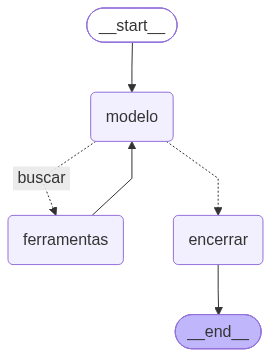

In [9]:
SISTEMA, CONTRATOS, FERRAMENTAS = ma.pecas_do_agente_unico()
ENCERRA = {"responder", "escalar_para_rh"}
camada = ma.camada                              # a camada do Encontro 2


class EstadoAgente(TypedDict, total=False):
    mensagens: Annotated[list, operator.add]    # a conversa com o modelo
    buscas: Annotated[list, operator.add]       # o registro da camada
    resultado: dict                             # desfecho, fontes, resposta


def chamadas_pedidas(estado: EstadoAgente) -> list:
    """As ferramentas que o modelo pediu na última mensagem dele."""
    ultima = estado["mensagens"][-1]
    return [modelo.Chamada(b["id"], b["name"], b["input"]) for b in ultima["content"] if b.get("type") == "tool_use"]


def no_modelo(estado: EstadoAgente) -> dict:
    """Uma chamada ao modelo. Ele é obrigado a pedir uma ferramenta: buscar, responder ou escalar."""
    resposta = modelo.chamar(estado["mensagens"], sistema=SISTEMA, ferramentas=FERRAMENTAS,
                             exigir_ferramenta=True)
    return {"mensagens": [modelo.mensagem_do_assistente(resposta)]}


def no_ferramentas(estado: EstadoAgente) -> dict:
    """Executa as buscas pedidas, pela camada do Encontro 2, e devolve os resultados ao modelo."""
    registro, pares = [], []
    for chamada in chamadas_pedidas(estado):
        pares.append((chamada, camada.executar(chamada.nome, chamada.args, CONTRATOS, registro)))
    return {"mensagens": [modelo.mensagem_de_resultados(pares)], "buscas": registro}


def no_encerrar(estado: EstadoAgente) -> dict:
    """Transforma a chamada de encerramento no contrato de saída."""
    chamada = next(c for c in chamadas_pedidas(estado) if c.nome in ENCERRA)
    if chamada.nome == "escalar_para_rh":
        return {"resultado": {"desfecho": "escalar", "fontes": [], "resposta": chamada.args.get("motivo", "")}}
    r = ma.Resultado.de_dict(chamada.args)
    return {"resultado": {"desfecho": r.desfecho, "fontes": r.fontes, "resposta": r.resposta}}


def depois_do_modelo(estado: EstadoAgente) -> str:
    """A decisão do modelo vira a aresta: buscar ou encerrar."""
    return "encerrar" if {c.nome for c in chamadas_pedidas(estado)} & ENCERRA else "buscar"


construtor = StateGraph(EstadoAgente)
construtor.add_node("modelo", no_modelo)
construtor.add_node("ferramentas", no_ferramentas)
construtor.add_node("encerrar", no_encerrar)
construtor.add_edge(START, "modelo")
construtor.add_conditional_edges("modelo", depois_do_modelo, {"buscar": "ferramentas", "encerrar": "encerrar"})
construtor.add_edge("ferramentas", "modelo")
construtor.add_edge("encerrar", END)
agente = construtor.compile()
desenhar(agente)

### O agente andando, passo a passo

O caso E1 pergunta o limite de alimentação numa viagem com pernoite em Brasília. A célula abaixo usa `stream` e imprime cada passo: o que o modelo pediu, que páginas a busca devolveu e o resultado final.

In [10]:
def mostrar_passo(atualizacao: dict) -> None:
    for no, mudou in atualizacao.items():
        if no == "modelo":
            pedidos = [f"{b['name']}({json.dumps(b['input'], ensure_ascii=False)[:90]})"
                       for b in mudou["mensagens"][0]["content"] if b.get("type") == "tool_use"]
            print(f"[modelo]      pediu: {', '.join(pedidos)}")
        elif no == "ferramentas":
            for bloco in mudou["mensagens"][0]["content"]:
                dados = json.loads(bloco["content"])
                print(f"[ferramentas] a busca devolveu: {[r['id'] for r in dados.get('resultados', [])]}")
        elif no == "encerrar":
            print(f"[encerrar]    {mudou['resultado']['desfecho']} · fontes {mudou['resultado']['fontes']}")
            print(f"              {mudou['resultado']['resposta'][:200]}")


pergunta = casos["E1"]["pergunta"]
print(pergunta, "\n")
for atualizacao in agente.stream({"mensagens": [modelo.mensagem_do_usuario(pergunta)]}, stream_mode="updates"):
    mostrar_passo(atualizacao)

Qual o limite diário de alimentação numa viagem com pernoite em Brasília? 

[modelo]      pediu: buscar_politicas({"pergunta": "limite diário de alimentação viagem pernoite Brasília"})
[ferramentas] a busca devolveu: ['fin-viagens-e-reembolso', 'fin-adiantamento-de-viagem', 'fin-adiantamento-de-viagem']
[modelo]      pediu: responder({"desfecho": "responder", "fontes": ["fin-viagens-e-reembolso"], "resposta": "O limite diá)
[encerrar]    responder · fontes ['fin-viagens-e-reembolso']
              O limite diário de alimentação em viagens com pernoite em Brasília é de R$ 160,00, desde que a diária de hotel não inclua jantar. Esse valor é aplicável a todas as refeições do dia, e bebidas alcoólic


Para conferir que é o mesmo agente, a mesma pergunta pelo laço escrito à mão no `multiagente.py`, o agente único do notebook 01:

In [11]:
r = ma.monolito()(pergunta, [], [])
print(f"laço à mão:  {r.desfecho} · fontes {r.fontes}")
print(f"grafo:       {agente.invoke({'mensagens': [modelo.mensagem_do_usuario(pergunta)]})['resultado']}")

laço à mão:  responder · fontes ['fin-viagens-e-reembolso']
grafo:       {'desfecho': 'responder', 'fontes': ['fin-viagens-e-reembolso'], 'resposta': 'O limite diário de alimentação em viagens com pernoite em Brasília é de R$ 160,00, desde que a diária de hotel não inclua jantar. Esse valor é aplicável a todas as refeições do dia, e bebidas alcoólicas não são reembolsadas.'}


### O critério de parada, no LangGraph

No laço à mão, o critério de parada era `MAX_PASSOS`. No LangGraph, ele se chama `recursion_limit`: o número máximo de passos que o grafo pode dar numa execução. Passou do limite, o LangGraph interrompe com um `GraphRecursionError`. É o mesmo componente do Encontro 1, agora no framework.

Para ver o limite funcionando, a célula abaixo dá ao agente só 2 passos: o tempo de chamar o modelo e executar uma busca, sem chance de responder.

In [12]:
from langgraph.errors import GraphRecursionError

try:
    agente.invoke({"mensagens": [modelo.mensagem_do_usuario(pergunta)]}, {"recursion_limit": 2})
except GraphRecursionError as erro:
    print("parou:", str(erro).splitlines()[0])

parou: Recursion limit of 2 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.


**Pergunta para a turma.**

- Onde está, no desenho, o "laço" do agente? E onde está o critério de parada?
- Na Parte 3, quem escolhia o caminho era um `if`. Aqui é o modelo. O que isso muda em testar o grafo?
- O `recursion_limit` encerra com um erro. No laço à mão, o limite encerrava escalando para o RH. Qual dos dois você quer em produção? Como faria o grafo escalar em vez de dar erro?

> **Para ir além (opcional).** O `create_agent` do LangChain, que apareceu na demonstração do Encontro 3, monta **exatamente este grafo** por baixo, já pronto. Aqui o grafo foi escrito à mão para que cada nó ficasse à vista, e porque assim ele passa pelo nosso `comum/modelo.py`.

## Parte 5 · Vários agentes: o roteador com especialistas como grafo

**Produz:** `roteado`, a arquitetura do notebook 01 como grafo.

### A ideia

No notebook 01, o roteador escolhia um especialista com um `if` sobre a resposta dele. Num grafo, essa escolha é uma **aresta condicional**: o nó `rotear` grava a rota no estado, e a aresta leva ao nó do especialista escolhido. Cada especialista é um nó, e por dentro ele é o mesmo laço da Parte 4, preso à sua parte da wiki.

```
                 ┌──► rh          ──┐
START ──► rotear ┼──► ti          ──┼──► END
                 ├──► beneficios  ──┤
                 └──► geral       ──┘
```

Cada nó de especialista é criado por uma pequena fábrica, `no_especialista(nome)`, para não repetir o mesmo código quatro vezes.

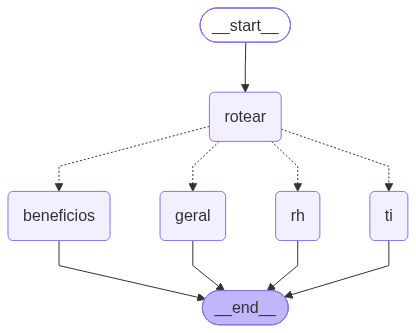

In [13]:
class EstadoAtendimento(TypedDict, total=False):
    pergunta: str
    rota: dict
    resultado: dict
    decisao: dict
    protocolo: str
    passos: Annotated[list, operator.add]


TIMES = ma.equipe(3)


def rotear(estado: EstadoAtendimento) -> dict:
    rota = ma.rotear_com_llm(estado["pergunta"], TIMES, [])
    return {"rota": rota, "passos": [f"rotear → {rota['destino']} ({rota['confianca']})"]}


def no_especialista(nome: str):
    """Fábrica: devolve o nó de um especialista, preso à sua parte da wiki."""
    atender = ma.especialista(nome)

    def no(estado: EstadoAtendimento) -> dict:
        r = atender(estado["pergunta"], [], [])
        return {"resultado": {"desfecho": r.desfecho, "fontes": r.fontes, "resposta": r.resposta},
                "passos": [f"especialista {nome} → {r.desfecho} {r.fontes}"]}
    return no


construtor = StateGraph(EstadoAtendimento)
construtor.add_node("rotear", rotear)
for nome in TIMES:
    construtor.add_node(nome, no_especialista(nome))
    construtor.add_edge(nome, END)
construtor.add_edge(START, "rotear")
construtor.add_conditional_edges("rotear", lambda estado: estado["rota"]["destino"], {n: n for n in TIMES})
roteado = construtor.compile()
desenhar(roteado)

In [14]:
for cid in ["T1", "C2", "P2"]:
    final = roteado.invoke({"pergunta": casos[cid]["pergunta"]})
    print(f"{cid} · {casos[cid]['pergunta'][:60]}")
    print("     " + "  |  ".join(final["passos"]) + "\n")

T1 · Estou com o erro 809 na VPN, o que eu faço?
     rotear → ti (alta)  |  especialista ti → responder ['ti-vpn-codigos-de-erro']

C2 · Qual o valor do auxílio home office?
     rotear → beneficios (alta)  |  especialista beneficios → escalar []

P2 · Obrigado, era isso mesmo que eu precisava!
     rotear → geral (alta)  |  especialista geral → responder []



### E o supervisor?

O supervisor do notebook 01 também cabe num grafo. O jeito mais direto é o da Parte 4: um nó `supervisor`, que chama o modelo, e os especialistas como as **ferramentas** dele, com uma aresta que volta ao supervisor depois de cada consulta. É o mesmo desenho do agente, com especialistas no lugar das buscas.

**Pergunta para a turma.** Compare o desenho deste grafo com o diagrama do roteador no notebook 01. O que o grafo deixou explícito que o código do notebook 01 escondia num `if`? E o que o grafo **não** mostra: onde está, no desenho, a parede de acesso de cada especialista?

## Parte 6 · Quando algo falha: checkpoint e retomada

**Produz:** `grafo`, o atendimento completo, com um checkpointer.

### O problema

Até aqui, o estado de cada execução existiu só durante o `invoke`. Se um passo falha no fim, depois que o modelo já respondeu e os tokens já foram pagos, não há de onde continuar: a única saída é começar de novo.

Um **checkpointer** resolve isso: ele salva o estado depois de cada nó que termina. Cada execução ganha um identificador, o `thread_id`, como o número de um atendimento, e com ele dá para consultar o estado salvo e **retomar** de onde parou.

### O atendimento completo

Para o grafo caber na tela, um nó só, `especialista`, chama o especialista da rota. Depois dele, uma decisão: se o especialista **escalou** (a pessoa perguntou se tem direito a um benefício), o atendimento passa por uma aprovação humana, na Parte 7. Em qualquer caso, termina registrado no Service Desk, um sistema lento, como no Encontro 2.

```
START ──► rotear ──► especialista ──┬── escalou ─────────► aprovar ──► registrar ──► END
                                    │                                      ▲
                                    └── respondeu ou "não sei" ────────────┘
```

Para a demonstração, o Service Desk falha na primeira vez (`FALHAS_NO_REGISTRO`), e `CONTAGEM` conta quantas vezes cada nó executou.

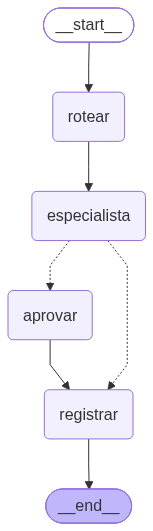

In [15]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command, interrupt

CONTAGEM = {"rotear": 0, "especialista": 0, "aprovar": 0, "registrar": 0}
FALHAS_NO_REGISTRO = [1]      # quantas vezes o Service Desk ainda vai falhar


def rotear_contando(estado: EstadoAtendimento) -> dict:
    CONTAGEM["rotear"] += 1
    return rotear(estado)


def atender(estado: EstadoAtendimento) -> dict:
    CONTAGEM["especialista"] += 1
    return no_especialista(estado["rota"]["destino"])(estado)


def depois_do_especialista(estado: EstadoAtendimento) -> str:
    return "aprovar" if estado["resultado"]["desfecho"] == "escalar" else "registrar"


def aprovar(estado: EstadoAtendimento) -> dict:
    """A ação irreversível do caso passa por uma pessoa. O grafo para aqui e espera (Parte 7)."""
    CONTAGEM["aprovar"] += 1
    decisao = interrupt({
        "acao": "comunicar ao colaborador a decisão sobre o benefício",
        "pergunta": estado["pergunta"],
        "o que o agente propõe": estado["resultado"]["resposta"],
    })
    return {"decisao": decisao, "passos": [f"aprovação humana → {decisao}"]}


def registrar(estado: EstadoAtendimento) -> dict:
    """Grava o atendimento no Service Desk. Na primeira vez, o sistema não responde."""
    CONTAGEM["registrar"] += 1
    if FALHAS_NO_REGISTRO[0] > 0:
        FALHAS_NO_REGISTRO[0] -= 1
        raise TimeoutError("Service Desk não respondeu em 30 s")
    return {"protocolo": f"SD-{len(estado['pergunta']) * 97 % 100000:05d}", "passos": ["registrar → ok"]}


construtor = StateGraph(EstadoAtendimento)
for nome, fn in [("rotear", rotear_contando), ("especialista", atender), ("aprovar", aprovar),
                 ("registrar", registrar)]:
    construtor.add_node(nome, fn)
construtor.add_edge(START, "rotear")
construtor.add_edge("rotear", "especialista")
construtor.add_conditional_edges("especialista", depois_do_especialista,
                                 {"aprovar": "aprovar", "registrar": "registrar"})
construtor.add_edge("aprovar", "registrar")
construtor.add_edge("registrar", END)
grafo = construtor.compile(checkpointer=InMemorySaver())     # a única diferença: o checkpointer
desenhar(grafo)

### Um passo falha no fim

O caso é o T1 (erro 809 na VPN). O roteador e o especialista rodam normalmente e gastam tokens. Depois, o registro no Service Desk falha. O `config` com o `thread_id` identifica este atendimento.

In [16]:
config = {"configurable": {"thread_id": "atendimento-T1"}}
medidor.zerar()
try:
    grafo.invoke({"pergunta": casos["T1"]["pergunta"]}, config)
except TimeoutError as erro:
    print("falhou:", erro)

retrato = grafo.get_state(config)
print("parou antes de:", retrato.next)
print("passos já salvos:", retrato.values["passos"])
print(f"chamadas ao modelo até aqui: {medidor.atual().chamadas} · US$ {medidor.atual().custo_usd:.5f}")
print("execuções por nó:", CONTAGEM)

falhou: Service Desk não respondeu em 30 s
parou antes de: ('registrar',)
passos já salvos: ['rotear → ti (alta)', "especialista ti → responder ['ti-vpn-codigos-de-erro']"]
chamadas ao modelo até aqui: 3 · US$ 0.00287
execuções por nó: {'rotear': 1, 'especialista': 1, 'aprovar': 0, 'registrar': 1}


### Como ler a saída

- **parou antes de** é o próximo nó que ainda precisa rodar: o `registrar`, que falhou.
- **passos já salvos** é o estado depois do último nó que terminou: a rota e a resposta do especialista estão guardadas.
- **chamadas ao modelo** é o que já foi gasto até a falha.

Agora a retomada: `grafo.invoke(None, config)` quer dizer "continue este atendimento de onde ele parou", sem entrada nova e com o mesmo `thread_id`.

In [17]:
antes = medidor.atual().chamadas
final = grafo.invoke(None, config)
print("protocolo:", final["protocolo"])
print("passos:", final["passos"])
print(f"chamadas ao modelo na retomada: {medidor.atual().chamadas - antes}")
print("execuções por nó:", CONTAGEM)

protocolo: SD-04171
passos: ['rotear → ti (alta)', "especialista ti → responder ['ti-vpn-codigos-de-erro']", 'registrar → ok']
chamadas ao modelo na retomada: 0
execuções por nó: {'rotear': 1, 'especialista': 1, 'aprovar': 0, 'registrar': 2}


Nenhuma chamada nova ao modelo, e na contagem o `rotear` e o `especialista` executaram uma vez só. Só o `registrar` rodou de novo.

### Para comparar: o mesmo atendimento sem checkpoint

A arquitetura do notebook 01, em Python puro, com o mesmo Service Desk falhando uma vez. Sem estado salvo, a única saída é repetir o atendimento inteiro.

In [18]:
FALHAS_NO_REGISTRO[0] = 1
arq = ma.roteador_especialistas("llm", 3)
medidor.zerar()
for tentativa in (1, 2):
    try:
        r = arq(casos["T1"]["pergunta"], [], [])
        registrar({"pergunta": casos["T1"]["pergunta"]})
        print(f"tentativa {tentativa}: ok")
        break
    except TimeoutError as erro:
        print(f"tentativa {tentativa}: {erro}. Repetindo tudo.")
print(f"chamadas ao modelo: {medidor.atual().chamadas} · US$ {medidor.atual().custo_usd:.5f}")

tentativa 1: Service Desk não respondeu em 30 s. Repetindo tudo.
tentativa 2: ok
chamadas ao modelo: 6 · US$ 0.00574


### Por que isso é mais que economia

A repetição custou o dobro. Mas há um problema maior, que a gravação esconde: aqui as duas tentativas deram a mesma resposta porque a segunda veio da gravação. **Ao vivo, o modelo pode responder diferente na segunda vez.** O colaborador já teria visto uma resposta, e o registro guardaria outra.

Num sistema determinístico, refazer um passo dá o mesmo resultado. Num sistema com modelo, não. Por isso, retomar do checkpoint é uma questão de **correção**: o que o colaborador viu e o que ficou registrado precisam ser a mesma coisa. É a auditabilidade, o terceiro problema de arquitetura do caso.

**Pergunta para a turma.** Onde mais, no caso da Aurora, refazer um passo mudaria o resultado?

> **Para ir além (opcional).** O `InMemorySaver` guarda os checkpoints na memória do processo, o que basta para aprender. Em produção, o checkpointer grava num banco (há implementações para Postgres, SQLite e Redis), e o atendimento sobrevive até a uma queda do servidor.

## Parte 7 · Esperar uma pessoa: a aprovação humana

**Produz:** um atendimento pausado, e depois retomado com a decisão de uma pessoa.

### A ideia

O caso é o X1: "Tenho um filho de 4 anos. Tenho direito ao auxílio-creche?". Pela regra 4 do Encontro 1, elegibilidade é decisão do RH, então o especialista escala. Comunicar essa decisão ao colaborador é a **ação irreversível** do caso, e por isso passa por uma pessoa.

No nó `aprovar`, a função `interrupt` faz o grafo **parar** e devolver um pedido: o que a analista precisa ver para decidir. O estado fica salvo pelo checkpointer. Quando a decisão chega, `Command(resume=…)` retoma o atendimento, e o valor passado vira o retorno do `interrupt`.

In [19]:
config = {"configurable": {"thread_id": "atendimento-X1"}}
parcial = grafo.invoke({"pergunta": casos["X1"]["pergunta"]}, config)

pendente = parcial.get("__interrupt__")
print("o grafo está esperando:", grafo.get_state(config).next)
if pendente:
    for chave, valor in pendente[0].value.items():
        print(f"  {chave}: {valor}")

o grafo está esperando: ('aprovar',)
  acao: comunicar ao colaborador a decisão sobre o benefício
  pergunta: Tenho um filho de 4 anos. Tenho direito ao auxílio-creche?
  o que o agente propõe: O colaborador está inquirindo sobre a elegibilidade ao auxílio-creche.


### O que aconteceu

O `invoke` voltou sem erro, mas o atendimento não terminou: o grafo está parado no nó `aprovar`, com o estado salvo. O conteúdo do `interrupt` é o pedido de aprovação, exatamente o que apareceria numa fila de tarefas do RH.

Neste ponto, o processo Python pode até acabar. Com um checkpointer persistente, a analista aprova amanhã, de outra máquina, e o atendimento continua do mesmo ponto, pelo mesmo `thread_id`. Agora, a decisão dela:

In [20]:
final = grafo.invoke(Command(resume={"aprovado": True, "analista": "Marina (Benefícios)",
                                     "observacao": "elegível; comunicar com o valor da faixa"}), config)
for passo in final["passos"]:
    print(" ·", passo)
print("protocolo:", final["protocolo"])

 · rotear → beneficios (alta)
 · especialista beneficios → escalar []
 · aprovação humana → {'aprovado': True, 'analista': 'Marina (Benefícios)', 'observacao': 'elegível; comunicar com o valor da faixa'}
 · registrar → ok
protocolo: SD-05626


### A pegadinha mais comum

Quando a execução retoma, **o nó interrompido roda de novo desde a primeira linha**. O `interrupt`, que da primeira vez parou o grafo, agora devolve a decisão. Tudo o que estiver **antes** do `interrupt`, dentro do nó, executa duas vezes.

Se houver ali uma chamada ao modelo, ela é paga duas vezes e pode responder diferente. Se houver o envio de um e-mail, o colaborador recebe dois. É o problema de **idempotência** do Encontro 2 aparecendo de novo: o que vem antes do `interrupt` precisa poder ser repetido sem efeito colateral.

**Pergunta para a turma.**

- Onde fica o checkpoint humano na arquitetura de vocês: antes da resposta, antes da ação, ou nos dois? Human-in-the-loop é uma decisão de arquitetura, e não um plano B para quando o agente falha.
- A coluna de reversibilidade do Tool Contract Sheet, do Encontro 2, diz quais ações não se desfazem. Quantas delas pediriam um `interrupt`?

## Parte 8 · Síntese

### O que você escreveu, e o que o LangGraph deu

| Você escreveu | O LangGraph deu |
|---|---|
| os nós: chamar o modelo, executar a busca, rotear, atender, registrar | a execução passo a passo, na ordem das arestas |
| as decisões: as funções das arestas condicionais | o desenho do fluxo, gerado do próprio código |
| o estado e como cada campo se junta (os reducers) | o estado salvo depois de cada passo, com um checkpointer |
| o contrato, a camada e a busca, dos Encontros 2 e 3 | a retomada depois de uma falha, pelo `thread_id` |
| onde uma pessoa precisa aprovar | a pausa durável com `interrupt` e a retomada com `Command` |
| — | o limite de passos (`recursion_limit`) |

A coluna da esquerda é o que define o agente: o que ele sabe fazer, o que ele pode ver e quando ele precisa de alguém. Ela continua sendo decisão da equipe, em qualquer framework.

### Quando o LangGraph se paga

- **Se paga** quando o fluxo tem vários passos caros, aprovação humana no meio, ou execuções que precisam sobreviver a falhas e esperar horas ou dias.
- **Não se paga** num agente único com uma ou duas ferramentas, que responde numa execução curta. Aí o grafo é estrutura sem benefício.

É a pergunta do dia, agora sobre frameworks: antes de acrescentar uma camada, pergunte se ela se paga.